# Práctica 7: Agrupamiento de datos (Clustering)

Se crea un modelo de K-Means para agrupar las canciones según sus características de audio, se elige el número de grupos con el método del codo y el coeficiente de silueta, y se describe qué tipo de canciones quedó en cada grupo.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PATH_INPUT = "../data/processed/spotify_cleaned.csv"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Carga de datos

Se deja una sola fila por canción (uri) para que las canciones que aparecen en varias semanas o países no pesen más que las demás.

In [2]:
df = pd.read_csv(PATH_INPUT)
canciones = df.drop_duplicates("uri").copy()
print(f"Canciones únicas: {len(canciones)}")

Canciones únicas: 2445


## Variables

Se usaran las mismas características de audio que en la práctica anterior. Como K-Means trabaja con distancias, se escalan las variables para que `tempo` o `loudness` no tenagn mayor peso por tener valores más grandes.

In [3]:
variables = ["danceability", "energy", "loudness", "speechiness", "acousticness", "valence", "tempo"]
X = StandardScaler().fit_transform(canciones[variables])

## Elección de k

Se prueba K-Means con k de 2 a 10 y se guarda la inercia (la suma de distancias al centro de cada grupo) y el coeficiente de silueta (mide qué tan separados quedan los grupos, entre -1 y 1).

In [4]:
ks = range(2, 11)
inercias = []
siluetas = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, etiquetas))

for k, i, s in zip(ks, inercias, siluetas):
    print(f"k = {k}  inercia = {i:.0f}  silueta = {s:.3f}")

k = 2  inercia = 13125  silueta = 0.276
k = 3  inercia = 11224  silueta = 0.223
k = 4  inercia = 9996  silueta = 0.175
k = 5  inercia = 9092  silueta = 0.177
k = 6  inercia = 8525  silueta = 0.171
k = 7  inercia = 8103  silueta = 0.161
k = 8  inercia = 7695  silueta = 0.169
k = 9  inercia = 7367  silueta = 0.164
k = 10  inercia = 7122  silueta = 0.143


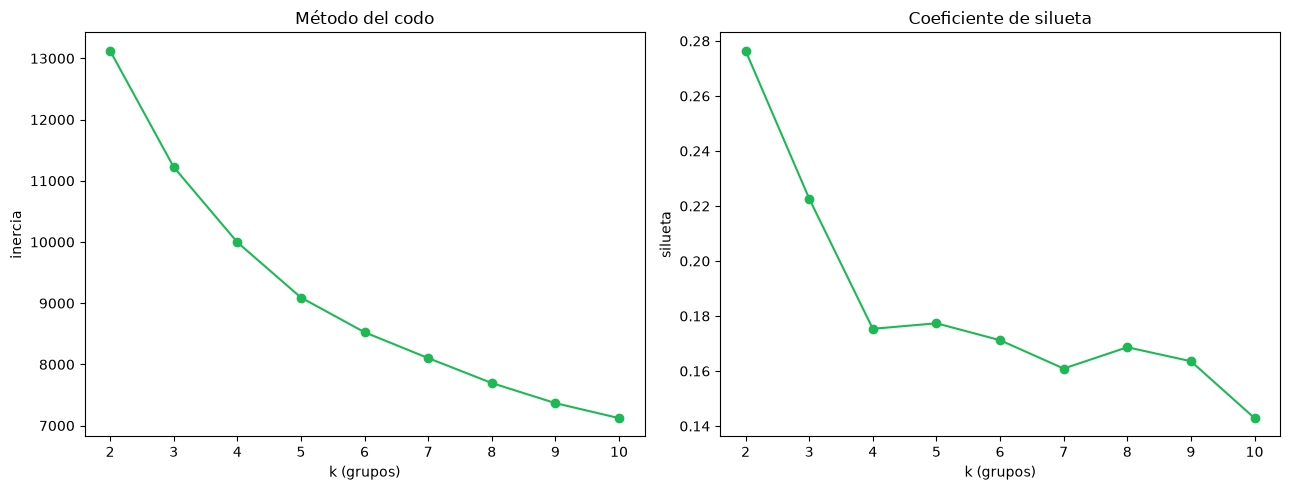

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# metodo del codo
axes[0].plot(ks, inercias, marker="o", color="#1DB954")
axes[0].set_xlabel("k (grupos)")
axes[0].set_ylabel("inercia")
axes[0].set_title("Método del codo")

# coeficiente de silueta
axes[1].plot(ks, siluetas, marker="o", color="#1DB954")
axes[1].set_xlabel("k (grupos)")
axes[1].set_ylabel("silueta")
axes[1].set_title("Coeficiente de silueta")

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "eleccion_k.png"), dpi=150)
plt.show()

La silueta más alta es con k = 2 pero dos grupos son muy generales. En metodo del codo la inercia baja bastante de K=2 a K=3 y después va bajando menos y la silueta con k=3 sigue siendo mejor que con K=4 o más, por lo que se tomara **k = 3**.

## Modelo final

In [6]:
k = 3
modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
canciones["grupo"] = modelo.fit_predict(X)

print(f"Silueta con k = {k}: {silhouette_score(X, canciones['grupo']):.3f}\n")
print(canciones["grupo"].value_counts().sort_index())

Silueta con k = 3: 0.223

grupo
0     535
1    1406
2     504
Name: count, dtype: int64


## Evaluación de los grupos

Para poder entender cada grupo veremos el promedio de cada variable y los géneros que más aparecen.

In [7]:
print(canciones.groupby("grupo")[variables].mean().round(3))

       danceability  energy  loudness  speechiness  acousticness  valence  \
grupo                                                                       
0             0.754   0.615    -7.040        0.297         0.189    0.530   
1             0.653   0.710    -5.736        0.066         0.126    0.534   
2             0.542   0.395    -9.782        0.065         0.628    0.364   

         tempo  
grupo           
0      123.197  
1      121.515  
2      115.210  


In [8]:
for g in range(k):
    print(f"Grupo {g}:")
    print(canciones[canciones["grupo"] == g]["artist_genre"].value_counts().head(5), "\n")

Grupo 0:
artist_genre
rap            72
hip hop        42
chicago rap    38
uk hip hop     38
trap           30
Name: count, dtype: int64 

Grupo 1:
artist_genre
pop          245
dance pop     85
uk pop        51
rap           51
0             39
Name: count, dtype: int64 

Grupo 2:
artist_genre
pop                     119
canadian pop             23
adult standards          21
rap                      20
contemporary country     15
Name: count, dtype: int64 



## Gráfica

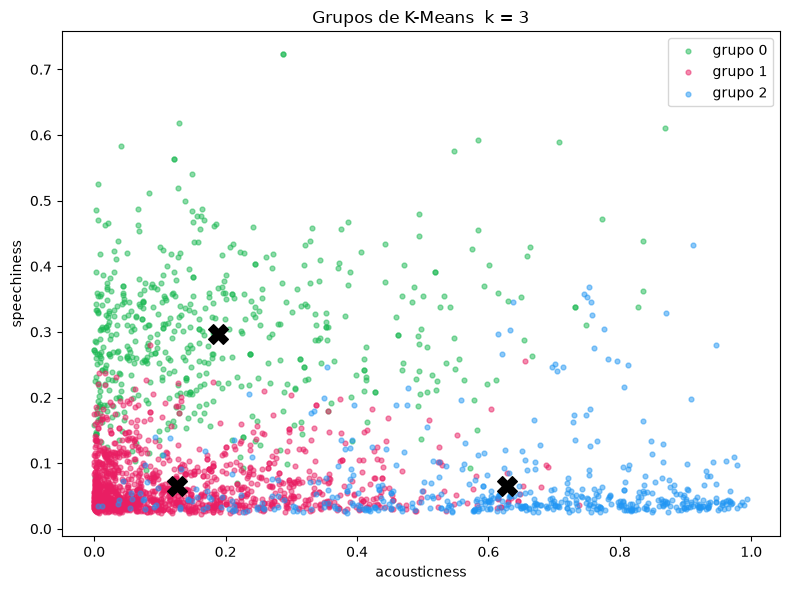

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
colores = ["#1DB954", "#E91E63", "#2196F3"]

# grupos por color y centro
centros = canciones.groupby("grupo")[["acousticness", "speechiness"]].mean()
for g in range(k):
    datos = canciones[canciones["grupo"] == g]
    ax.scatter(datos["acousticness"], datos["speechiness"], s=12, alpha=0.5, color=colores[g], label=f"grupo {g}")
    ax.scatter(centros.loc[g, "acousticness"], centros.loc[g, "speechiness"], s=200, marker="X", color="black")

ax.set_xlabel("acousticness")
ax.set_ylabel("speechiness")
ax.set_title(f"Grupos de K-Means  k = {k}")
ax.legend()

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "kmeans_grupos.png"), dpi=150)
plt.show()

Con k = 3 el modelo separa las canciones en tres grupos que tienen en su mayoria una buena logica de agrupacion musical:

* Grupo 0: Este grupo tiene el mayor `speechiness` (0.297) y `danceability` (0.754). Aquí se agrupó casi todo el rap, hip hop y trap, es decir, canciones donde predomina la voz hablada.
* Grupo 1: Este grupo tiene el `energy` (0.710) y el `loudness` (-5.7 dB) más altos y poca `acousticness`. Esto es porque se agruparon principalmente canciones de pop y dance pop, que son las más comunes en las listas.
* Grupo 2: Este grupo tiene mayor `acousticness` (0.628) y menor `energy` (0.395) y `valence` (0.364). Aqui se agruparon canciones más tranquilas o tristes, como baladas pop, adult standards y country, por eso los valores de enegy y valence son mas bajos y acousticness es el mas alto.

La silueta de 0.223 indica que los grupos se separan pero no de forma muy marcada. Esto se puede ver en la gráfica, donde los grupos 1 y 2 se mezclan en la zona de baja `acousticness` y no hay límites claros entre ellos, ya que las canciones no se dividen en tipos totalmente distintos sino que cambian poco a poco de una a otra. Aun así, K-Means logra encontrar los tres perfiles principales (rap, pop energético y canciones acústicas) sin usar la etiqueta de género.